# Numerical Optimization of gut-immune interactions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from math import erf
import numba as nb
import multiprocessing as mp
from tqdm import tqdm
from joblib import Parallel, delayed
import os
from sklearn.feature_selection import mutual_info_classif

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

In [2]:
# Define model parameters
nr, ng, nb = 5, 5, 5 # (receptors, microbes, resources)

F = np.random.uniform(size=(ng,nr)) # cross-reactivity: F_i,r = f_r,i
A = -np.eye(ng) # species competition matrix
b = np.random.uniform(size = nb) # resource abundance
C = 5*np.random.uniform(size=(ng,nb)) # resource utilization matrix
D0 = np.random.uniform(size=(nb,ng)) # resource benefit matrix
mu = np.random.uniform(size = ng) # rates of breaching gut epithelium

# Define functions
def h(gam):
    return gam

def lam(P, gam):
    return h(gam)*F.dot(P)

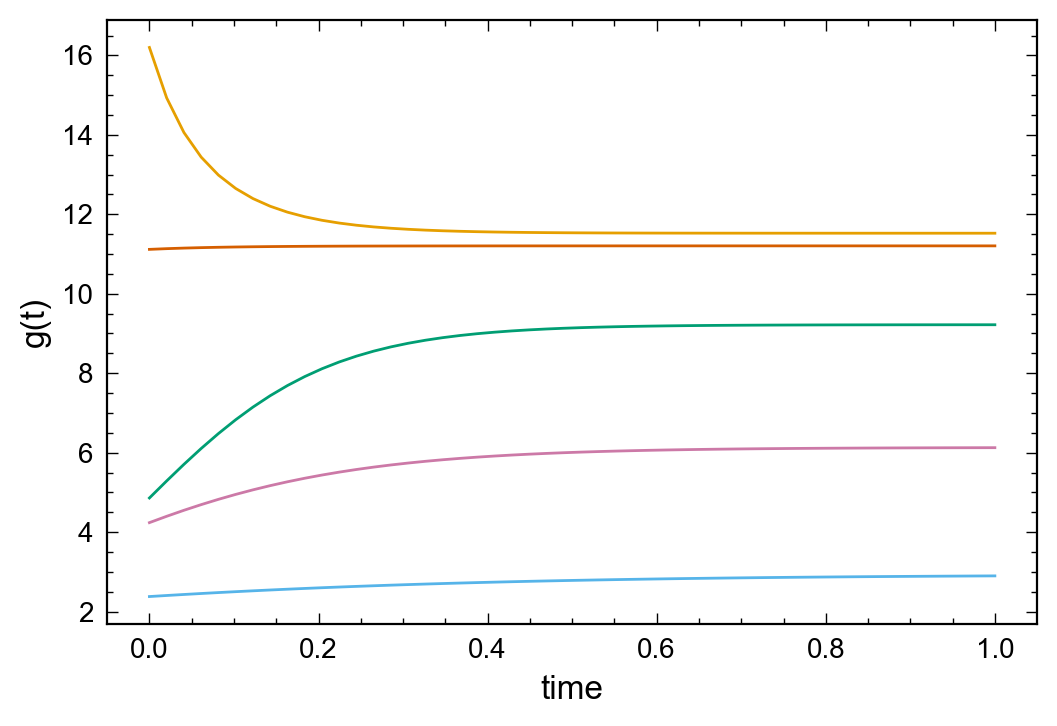

In [3]:
# Simulate microbe dynamics
from scipy.integrate import odeint

P0 = np.random.dirichlet(np.ones(nr))
gam0 = 0.5

# function that returns dx/dt = A x 
def model(g,t):
    dgdt = (-lam(P0,gam0) + C.dot(b) + A.dot(g)).dot(np.diag(g))
    return list(dgdt.ravel())

# initial condition
g0 = 20*np.random.rand(ng)

# time points
t = np.linspace(0,1)

# solve ODE
g = odeint(model,list(g0),t)

# plot results
plt.plot(t,g)
plt.xlabel('time')
plt.ylabel('g(t)')
plt.show()

In [10]:
# Define parameters
beta = 0.1

# Define cost function
def g_ss(P,gam):
    return np.linalg.solve(A, lam(P, gam) - C.dot(b))

def B(P,gam):
    return b.T.dot(D0.dot(g_ss(P,gam)))

def cost(P,gam):
    return (1-h(gam)*P).dot(g_ss(P,gam)*mu) - beta*B(P,gam)

In [11]:
cost(P0,gam0)

13.943527972448424

In [ ]:
# Implement proximal gradient optimization for repertoire: https://pypi.org/project/pyproximal/